## Loading Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,OrdinalEncoder
from sklearn.model_selection import train_test_split

## Dataset Loading

In [2]:
file = "dataset/student_placement_data.csv"

df = pd.read_csv(file)

df.head() #display first 5 records

,Feature_ID,Math_Score,ICT_Score,Gender,Program
0,1,78.0,76.0,M,Electronics
1,2,NaN,49.0,F,Mechanical
2,3,68.0,49.0,M,Mechanical
3,4,54.0,58.0,M,Automotive
4,5,82.0,56.0,M,Mechanical


## dataset info

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Feature_ID  1000 non-null   int64  
 1   Math_Score  950 non-null    float64
 2   ICT_Score   950 non-null    float64
 3   Gender      970 non-null    str    
 4   Program     1000 non-null   str    
dtypes: float64(2), int64(1), str(2)
memory usage: 39.2 KB


## dataset length (number of rows)

In [4]:
len(df)

1000

In [5]:
df.shape

(1000, 5)

## STATISTICAL ANALYSIS

In [6]:
df.describe()

,Feature_ID,Math_Score,ICT_Score
count,1000.000000,950.000000,950.000000
mean,500.500000,70.863158,70.060000
std,288.819436,17.654816,17.245808
min,1.000000,40.000000,40.000000
25%,250.750000,56.000000,56.000000
50%,500.500000,71.000000,70.000000
75%,750.250000,86.750000,85.000000
max,1000.000000,100.000000,100.000000


In [7]:
df.min()

Feature_ID             1
Math_Score          40.0
ICT_Score           40.0
Gender                 F
Program       Automotive
dtype: object

In [8]:
df.Math_Score.min()

np.float64(40.0)

In [9]:
df['Math_Score'].median()

np.float64(71.0)

In [10]:
# Column names

df.columns

Index(['Feature_ID', 'Math_Score', 'ICT_Score', 'Gender', 'Program'], dtype='str')

## check and remove duplicate

In [11]:
print(df.duplicated().sum())
df.drop_duplicates()

0


,Feature_ID,Math_Score,ICT_Score,Gender,Program
0,1,78.0,76.0,M,Electronics
1,2,NaN,49.0,F,Mechanical
2,3,68.0,49.0,M,Mechanical
3,4,54.0,58.0,M,Automotive
4,5,82.0,56.0,M,Mechanical
...,...,...,...,...,...
995,996,42.0,91.0,F,Electronics
996,997,92.0,68.0,M,Mechanical
997,998,62.0,88.0,M,Electronics
998,999,76.0,68.0,F,Automotive


In [12]:
df = df.drop('Feature_ID', axis=1)
df.head()

,Math_Score,ICT_Score,Gender,Program
0,78.0,76.0,M,Electronics
1,NaN,49.0,F,Mechanical
2,68.0,49.0,M,Mechanical
3,54.0,58.0,M,Automotive
4,82.0,56.0,M,Mechanical


In [13]:
# check missing values
print(df.isna().sum())
print(df.isnull().sum())


Math_Score    50
ICT_Score     50
Gender        30
Program        0
dtype: int64
Math_Score    50
ICT_Score     50
Gender        30
Program        0
dtype: int64


## Detecting outlier using IQR

In [14]:


# Calculate Q1 and Q3
Q1 = df['Math_Score'].quantile(0.25)
Q3 = df['Math_Score'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect outliers
outliers = df[
    (df['Math_Score'] < lower_bound) |
    (df['Math_Score'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nNumber of outliers:", len(outliers))
print("\nOutliers:")
print(outliers)

Q1: 56.0
Q3: 86.75
IQR: 30.75
Lower Bound: 9.875
Upper Bound: 132.875

Number of outliers: 0

Outliers:
Empty DataFrame
Columns: [Math_Score, ICT_Score, Gender, Program]
Index: []


## Outlier detection using BOX PLOT

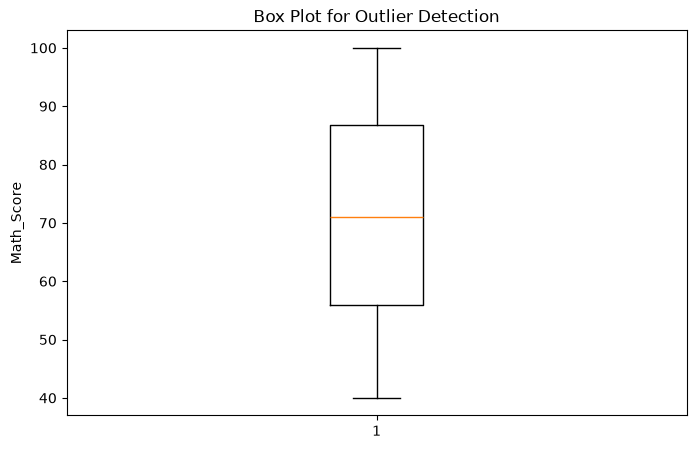

In [15]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['Math_Score'].dropna())

plt.title('Box Plot for Outlier Detection')
plt.ylabel('Math_Score')

plt.show()

## Handle Missing values using Mean bcz no outlier ditected in both feature

In [16]:
# Math_score
df['Math_Score'] = df['Math_Score'].fillna(
    df['Math_Score'].mean()
)

# ICT_score
df['ICT_Score'] = df['ICT_Score'].fillna(
    df['ICT_Score'].mean()
)


## Handle Missing values using Mode for Gender bcz it is categorical feature

In [17]:
# ICT_score
df['Gender'] = df['Gender'].fillna(
    df['Gender'].mode()[0]
)

In [18]:
df.isna().sum()

Math_Score    0
ICT_Score     0
Gender        0
Program       0
dtype: int64

In [19]:
df.head()

,Math_Score,ICT_Score,Gender,Program
0,78.000000,76.0,M,Electronics
1,70.863158,49.0,F,Mechanical
2,68.000000,49.0,M,Mechanical
3,54.000000,58.0,M,Automotive
4,82.000000,56.0,M,Mechanical


In [20]:
gender_scaler = LabelEncoder()
df['Gender'] = gender_scaler.fit_transform(df['Gender'].astype(str))

In [21]:
gender_mapping = pd.DataFrame({
    'Category': gender_scaler.classes_,
    'Encoded_Value': gender_scaler.transform(gender_scaler.classes_)
})

print(gender_mapping)

  Category  Encoded_Value
0        F              0
1        M              1


## Use Ordinal/label encoding for Program (target)

In [22]:
# Create ordinal encoder
program_encoder = OrdinalEncoder()

# Encode Program
df['Program'] = program_encoder.fit_transform(df[['Program']]).astype(int)

# Show categories and their encoded values
for value, category in enumerate(program_encoder.categories_[0]):
    print(f"{category} -> {value}")

Automotive -> 0
Electronics -> 1
ICT -> 2
Mechanical -> 3


## FEATURE SCALING (USE MIN-MAX NORMARIZATION)

In [23]:
df['Math_Score'] = (df['Math_Score']-df.Math_Score.min())/(df.Math_Score.max()-df.Math_Score.min())
df['ICT_Score'] = (df['ICT_Score']-df.ICT_Score.min())/(df.ICT_Score.max()-df.ICT_Score.min())

In [24]:
df.head()

,Math_Score,ICT_Score,Gender,Program
0,0.633333,0.600000,1,1
1,0.514386,0.150000,0,3
2,0.466667,0.150000,1,3
3,0.233333,0.300000,1,0
4,0.700000,0.266667,1,3


## save the clean dataset

In [25]:
df.to_csv("dataset/student_placement_data_cleaned.csv", index=False)

## Feature splitting

In [26]:
# X = df[['Math_Score', 'ICT_Score']]
X = df.drop('Program', axis=1)
y = df['Program']

In [27]:
X

,Math_Score,ICT_Score,Gender
0,0.633333,0.600000,1
1,0.514386,0.150000,0
2,0.466667,0.150000,1
3,0.233333,0.300000,1
4,0.700000,0.266667,1
...,...,...,...
995,0.033333,0.850000,0
996,0.866667,0.466667,1
997,0.366667,0.800000,1
998,0.600000,0.466667,0


In [28]:
y

0      1
1      3
2      3
3      0
4      3
      ..
995    1
996    3
997    1
998    0
999    2
Name: Program, Length: 1000, dtype: int64

## Dataset Splitting

In [29]:
X_train, X_test, y_train,y_test = train_test_split(X,y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (800, 3)
X_test shape: (200, 3)
y_train shape: (800,)
y_test shape: (200,)
